In [1]:
#1. Import Required Libraries
#We use pandas for data manipulation and analysis, and yfinance to fetch historical stock market data.
import pandas as pd

In [2]:
import yfinance as yf
import matplotlib.pyplot as plt

In [3]:
#2. Fetch Historical Stock Data
# We download one year of daily market data for Reliance Industries using its Yahoo Finance ticker RELIANCE.NS.
#The .NS suffix represents the NSE-listed version of the stock.

data = yf.download("RELIANCE.NS", period="1y")

[*********************100%***********************]  1 of 1 completed


In [4]:
data.head()

Price,Close,High,Low,Open,Volume
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS
Date,,,,,
2025-09-25,1366.083862,1378.128150,1362.699486,1374.942926,11411143
2025-09-26,1371.259888,1376.336392,1359.713298,1365.685685,9879109
2025-09-29,1366.481934,1382.607327,1361.703976,1375.241360,14231999
2025-09-30,1357.722412,1370.762097,1356.527984,1370.762097,14604684
2025-10-01,1362.400757,1372.255218,1356.428371,1360.708629,12045916


In [5]:
#3. Inspect the Downloaded Data
# We display the first few rows to understand the structure of the dataset and the available market variables.

data.shape

(252, 5)

In [6]:
# Display the available columns in the dataset.
# This helps us identify the price and volume variables available for analysis.
data.columns

MultiIndex([( 'Close', 'RELIANCE.NS'),
            (  'High', 'RELIANCE.NS'),
            (   'Low', 'RELIANCE.NS'),
            (  'Open', 'RELIANCE.NS'),
            ('Volume', 'RELIANCE.NS')],
           names=['Price', 'Ticker'])

In [7]:
# Check the dataset structure, data types, and number of non-null values.
# This helps us identify missing values and verify that the data is suitable for analysis.
data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 252 entries, 2025-09-25 to 2026-09-25
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   (Close, RELIANCE.NS)   252 non-null    float64
 1   (High, RELIANCE.NS)    252 non-null    float64
 2   (Low, RELIANCE.NS)     252 non-null    float64
 3   (Open, RELIANCE.NS)    252 non-null    float64
 4   (Volume, RELIANCE.NS)  252 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.8 KB


In [8]:
# Calculate the daily percentage return of the stock.
# This measures the percentage change in closing price from one trading day to the next.
data["Close"].pct_change()

Ticker,RELIANCE.NS
Date,
2025-09-25,NaN
2025-09-26,0.003789
2025-09-29,-0.003484
2025-09-30,-0.006410
2025-10-01,0.003446
...,...
2026-09-21,0.017123
2026-09-22,-0.005612
2026-09-23,0.006127


In [9]:
# Display the closing price and calculated daily return together.
# This helps us verify that the return calculation has been added correctly.
data["Return"] = data["Close"].pct_change()

In [10]:
data.head()


Price,Close,High,Low,Open,Volume,Return
Ticker,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,RELIANCE.NS,
Date,,,,,,
2025-09-25,1366.083862,1378.128150,1362.699486,1374.942926,11411143,NaN
2025-09-26,1371.259888,1376.336392,1359.713298,1365.685685,9879109,0.003789
2025-09-29,1366.481934,1382.607327,1361.703976,1375.241360,14231999,-0.003484
2025-09-30,1357.722412,1370.762097,1356.527984,1370.762097,14604684,-0.006410
2025-10-01,1362.400757,1372.255218,1356.428371,1360.708629,12045916,0.003446


In [11]:
data[["Close", "Return"]].head()

Price,Close,Return
Ticker,RELIANCE.NS,
Date,,
2025-09-25,1366.083862,NaN
2025-09-26,1371.259888,0.003789
2025-09-29,1366.481934,-0.003484
2025-09-30,1357.722412,-0.006410
2025-10-01,1362.400757,0.003446


In [12]:
# Generate descriptive statistics for the daily returns.
# This summarizes the average return, volatility, extreme returns, and return distribution.
data["Return"].describe()

count    251.000000
mean      -0.000347
std        0.012945
min       -0.045998
25%       -0.008328
50%       -0.000077
75%        0.006093
max        0.035291
Name: Return, dtype: float64

In [13]:
# Find the date on which the stock recorded its highest daily return.
# idxmax() returns the index (date) corresponding to the maximum return.
data["Return"].idxmax()

Timestamp('2025-10-20 00:00:00')

In [14]:
# Find the date on which the stock recorded its lowest daily return.
# idxmin() returns the index (date) corresponding to the minimum return.
data["Return"].idxmin()

Timestamp('2026-03-27 00:00:00')

In [15]:
# Retrieve the actual return value from the stock's best trading day.
# idxmax() identifies the date, and loc[] retrieves the return recorded on that date.
data.loc[data["Return"].idxmin(), "Return"]

np.float64(-0.04599812997457742)

In [16]:
# Retrieve the actual return value from the stock's worst trading day.
# idxmin() identifies the date, and loc[] retrieves the return recorded on that date.
data.loc[data["Return"].idxmax(), "Return"]

np.float64(0.035290716445324666)

In [17]:
# Calculate the standard deviation of daily returns.
# This measures how much the stock's daily returns varied during the entire period.
data["Return"].std()

np.float64(0.012945202219275462)

In [18]:
# Calculate volatility using a rolling window of the most recent 30 trading days.
# This helps us observe how the stock's volatility changed over time.
data["Rolling_Volatility"] = data["Return"].rolling(30).std()

In [19]:
# Display the most recent daily returns and 30-day rolling volatility values.
# This allows us to inspect recent changes in the stock's return variability.
data[["Return", "Rolling_Volatility"]].tail()

Price,Return,Rolling_Volatility
Ticker,,
Date,,
2026-09-21,0.017123,0.010021
2026-09-22,-0.005612,0.010042
2026-09-23,0.006127,0.010097
2026-09-24,-0.023077,0.010738
2026-09-25,0.005577,0.010823


In [20]:
# Find the highest 30-day rolling volatility observed during the analysis period.
# This identifies the point when recent daily return variability was at its highest.
data["Rolling_Volatility"].max()


np.float64(0.019598911611937248)

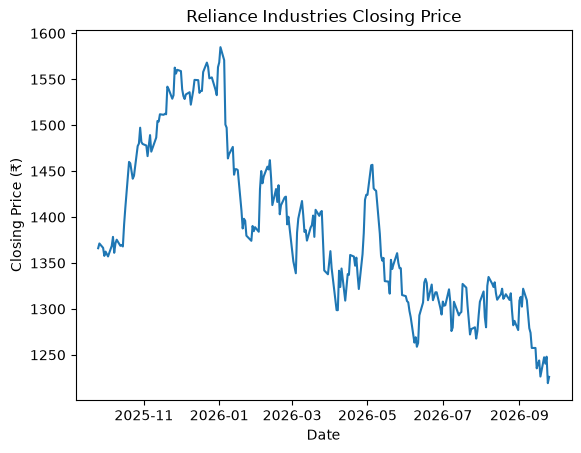

In [21]:
# Plot the closing price over time.
# This helps us visually understand how Reliance's stock price changed during the analysis period.

plt.plot(data.index, data["Close"])
plt.title("Reliance Industries Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (₹)")
plt.show()

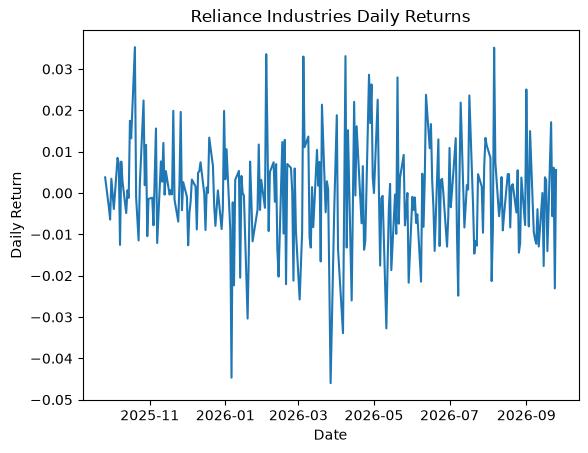

In [22]:
plt.plot(data.index, data["Return"])
plt.title("Reliance Industries Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.show()

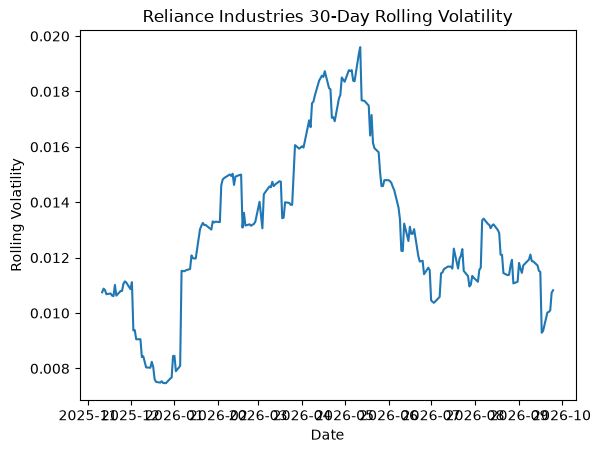

In [23]:
# Plot 30-day rolling volatility over time.
# This helps us identify periods when Reliance's daily returns became more or less volatile.
plt.plot(data.index, data["Rolling_Volatility"])
plt.title("Reliance Industries 30-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Rolling Volatility")
plt.show()

In [24]:
# Calculate the highest closing price reached up to each trading day.
# This running peak will be used as the reference point for measuring drawdown.
data["Peak"] = data["Close"].cummax()
data[["Close", "Peak"]].tail()

Price,Close,Peak
Ticker,RELIANCE.NS,
Date,,
2026-09-21,1247.400024,1584.971802
2026-09-22,1240.400024,1584.971802
2026-09-23,1248.000000,1584.971802
2026-09-24,1219.199951,1584.971802
2026-09-25,1226.000000,1584.971802


In [25]:
data["Close"].columns


Index(['RELIANCE.NS'], dtype='str', name='Ticker')

In [26]:
data["Peak"].head()


Date
2025-09-25    1366.083862
2025-09-26    1371.259888
2025-09-29    1371.259888
2025-09-30    1371.259888
2025-10-01    1371.259888
Name: Peak, dtype: float64

In [27]:
close_price = data["Close"]["RELIANCE.NS"]

In [28]:
close_price.head()

Date
2025-09-25    1366.083862
2025-09-26    1371.259888
2025-09-29    1366.481934
2025-09-30    1357.722412
2025-10-01    1362.400757
Name: RELIANCE.NS, dtype: float64

In [29]:
# Calculate the percentage decline from the previous peak.
# A negative value shows how far the current price is below its previous highest price.
data["Drawdown"] = (close_price - data["Peak"]) / data["Peak"]
data[["Close", "Peak", "Drawdown"]].tail()

Price,Close,Peak,Drawdown
Ticker,RELIANCE.NS,,
Date,,,
2026-09-21,1247.400024,1584.971802,-0.212983
2026-09-22,1240.400024,1584.971802,-0.217399
2026-09-23,1248.000000,1584.971802,-0.212604
2026-09-24,1219.199951,1584.971802,-0.230775
2026-09-25,1226.000000,1584.971802,-0.226485


In [30]:
# Find the largest peak-to-trough decline observed during the analysis period.
# The minimum drawdown represents the maximum historical decline from a previous peak.
data["Drawdown"].min()


np.float64(-0.23077498929651513)

In [31]:
# Find the date when the maximum drawdown occurred.
# This identifies the point at which the stock was furthest below its previous peak.

data["Drawdown"].idxmin()

Timestamp('2026-09-24 00:00:00')

In [32]:
# Find the peak price from which the maximum drawdown occurred.
# This helps us identify the previous high before the largest decline.

data.loc[data["Drawdown"].idxmin(), "Peak"]

np.float64(1584.9718017578125)

In [33]:
# Retrieve the maximum drawdown value.
# This shows the largest percentage decline from a previous peak during the analysis period.

data["Drawdown"].min()

np.float64(-0.23077498929651513)

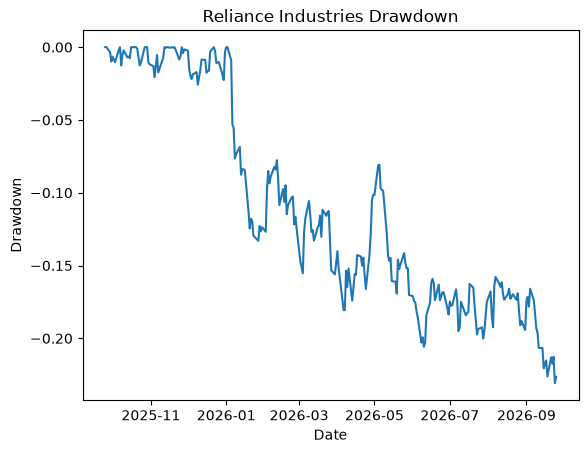

In [34]:
# Plot the drawdown over time.
# This helps us visually identify periods when Reliance was significantly below its previous peak.
plt.plot(data.index, data["Drawdown"])

plt.title("Reliance Industries Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown")

plt.show()

In [35]:
# Download one year of daily market data for TCS.
# This allows us to apply the same financial analysis used for Reliance.
tcs_data = yf.download("TCS.NS", period="1y")
tcs_data.shape

[*********************100%***********************]  1 of 1 completed


(252, 5)

In [36]:
# Download one year of daily market data for Infosys.
# This allows us to apply the same stock analysis to a second IT company.
infy_data = yf.download("INFY.NS", period="1y")
infy_data.shape

[*********************100%***********************]  1 of 1 completed


(252, 5)

In [37]:
# Calculate the daily percentage return for TCS.
# This measures the day-to-day change in TCS's closing price.

tcs_data["Return"] = tcs_data["Close"].pct_change()

In [38]:
# Calculate the daily percentage return for Infosys.
# This measures the day-to-day change in Infosys's closing price.

infy_data["Return"] = infy_data["Close"].pct_change()

In [39]:
# Calculate the standard deviation of TCS daily returns.
# This measures the historical variability of TCS's daily returns.

tcs_volatility = tcs_data["Return"].std()

In [40]:
# Calculate the standard deviation of Infosys daily returns.
# This measures the historical variability of Infosys's daily returns.

infy_volatility = infy_data["Return"].std()

In [41]:
# Calculate 30-day rolling volatility for TCS.
# This measures how TCS's daily return variability changes over time.

tcs_data["Rolling_Volatility"] = tcs_data["Return"].rolling(30).std()

In [42]:
# Calculate 30-day rolling volatility for Infosys.
# This measures how Infosys's daily return variability changes over time.

infy_data["Rolling_Volatility"] = infy_data["Return"].rolling(30).std()

In [43]:
# Calculate the highest closing price reached by TCS up to each trading day.
# This running peak will be used to measure TCS's drawdown.

tcs_close = tcs_data["Close"]["TCS.NS"]
tcs_data["Peak"] = tcs_close.cummax()

In [44]:
# Calculate the highest closing price reached by Infosys up to each trading day.
# This running peak will be used to measure Infosys's drawdown.

infy_close = infy_data["Close"]["INFY.NS"]
infy_data["Peak"] = infy_close.cummax()

In [45]:
# Calculate TCS's percentage decline from its previous peak.
# Negative values show how far TCS is below its previous highest closing price.

tcs_data["Drawdown"] = (tcs_close - tcs_data["Peak"]) / tcs_data["Peak"]

In [46]:
# Calculate Infosys's percentage decline from its previous peak.
# Negative values show how far Infosys is below its previous highest closing price.

infy_data["Drawdown"] = (infy_close - infy_data["Peak"]) / infy_data["Peak"]

In [47]:
# Calculate the average daily return for each stock.
# This shows the average percentage return generated on a typical trading day.

reliance_avg_return = data["Return"].mean()
tcs_avg_return = tcs_data["Return"].mean()
infy_avg_return = infy_data["Return"].mean()

print("Reliance average daily return:", reliance_avg_return)
print("TCS average daily return:", tcs_avg_return)
print("Infosys average daily return:", infy_avg_return)

Reliance average daily return: -0.00034740981318441994
TCS average daily return: -0.0010765936406885877
Infosys average daily return: -0.0012503496851049307


In [48]:
# Find the best and worst single trading day for each stock.
# This helps us understand the extreme daily movements in each stock.

print("Reliance best day:", data["Return"].max())
print("Reliance worst day:", data["Return"].min())

print("TCS best day:", tcs_data["Return"].max())
print("TCS worst day:", tcs_data["Return"].min())

print("Infosys best day:", infy_data["Return"].max())
print("Infosys worst day:", infy_data["Return"].min())

Reliance best day: 0.035290716445324666
Reliance worst day: -0.04599812997457742
TCS best day: 0.06507358393714768
TCS worst day: -0.08386122221554515
Infosys best day: 0.05679838726070363
Infosys worst day: -0.07258454969424133


In [49]:
# Find the maximum drawdown for each stock.
# This shows the largest percentage decline from a previous peak during the period.

reliance_max_drawdown = data["Drawdown"].min()
tcs_max_drawdown = tcs_data["Drawdown"].min()
infy_max_drawdown = infy_data["Drawdown"].min()

print("Reliance maximum drawdown:", reliance_max_drawdown)
print("TCS maximum drawdown:", tcs_max_drawdown)
print("Infosys maximum drawdown:", infy_max_drawdown)

Reliance maximum drawdown: -0.23077498929651513
TCS maximum drawdown: -0.3846394202581857
Infosys maximum drawdown: -0.4042956209303335


In [50]:
# Create a comparison table for the three stocks.
# This organizes the main risk and return metrics in one place.

comparison = pd.DataFrame({
    "Stock": ["Reliance", "TCS", "Infosys"],
    "Average Daily Return": [
        reliance_avg_return,
        tcs_avg_return,
        infy_avg_return
    ],
    "Volatility": [
        data["Return"].std(),
        tcs_volatility,
        infy_volatility
    ],
    "Best Day": [
        data["Return"].max(),
        tcs_data["Return"].max(),
        infy_data["Return"].max()
    ],
    "Worst Day": [
        data["Return"].min(),
        tcs_data["Return"].min(),
        infy_data["Return"].min()
    ],
    "Maximum Drawdown": [
        reliance_max_drawdown,
        tcs_max_drawdown,
        infy_max_drawdown
    ]
})

comparison

,Stock,Average Daily Return,Volatility,Best Day,Worst Day,Maximum Drawdown
0,Reliance,-0.000347,0.012945,0.035291,-0.045998,-0.230775
1,TCS,-0.001077,0.017809,0.065074,-0.083861,-0.384639
2,Infosys,-0.001250,0.018810,0.056798,-0.072585,-0.404296


In [51]:
# Convert return, volatility, and drawdown values into percentages.
# This makes the comparison table easier to understand and present.

comparison["Average Daily Return"] = comparison["Average Daily Return"] * 100
comparison["Volatility"] = comparison["Volatility"] * 100
comparison["Best Day"] = comparison["Best Day"] * 100
comparison["Worst Day"] = comparison["Worst Day"] * 100
comparison["Maximum Drawdown"] = comparison["Maximum Drawdown"] * 100

comparison

,Stock,Average Daily Return,Volatility,Best Day,Worst Day,Maximum Drawdown
0,Reliance,-0.034741,1.294520,3.529072,-4.599813,-23.077499
1,TCS,-0.107659,1.780938,6.507358,-8.386122,-38.463942
2,Infosys,-0.125035,1.881027,5.679839,-7.258455,-40.429562


In [52]:
# Find the date when each stock experienced its maximum drawdown.
# This tells us when the largest decline from a previous peak occurred.

reliance_max_dd_date = data["Drawdown"].idxmin()
tcs_max_dd_date = tcs_data["Drawdown"].idxmin()
infy_max_dd_date = infy_data["Drawdown"].idxmin()

print("Reliance maximum drawdown date:", reliance_max_dd_date)
print("TCS maximum drawdown date:", tcs_max_dd_date)
print("Infosys maximum drawdown date:", infy_max_dd_date)

Reliance maximum drawdown date: 2026-09-24 00:00:00
TCS maximum drawdown date: 2026-07-01 00:00:00
Infosys maximum drawdown date: 2026-07-01 00:00:00


In [53]:
# Normalize each stock's closing price to 100 at the beginning of the period.
# This allows us to compare their relative performance despite different share prices.

reliance_close = data["Close"]["RELIANCE.NS"]
tcs_close = tcs_data["Close"]["TCS.NS"]
infy_close = infy_data["Close"]["INFY.NS"]

reliance_normalized = reliance_close / reliance_close.iloc[0] * 100
tcs_normalized = tcs_close / tcs_close.iloc[0] * 100
infy_normalized = infy_close / infy_close.iloc[0] * 100

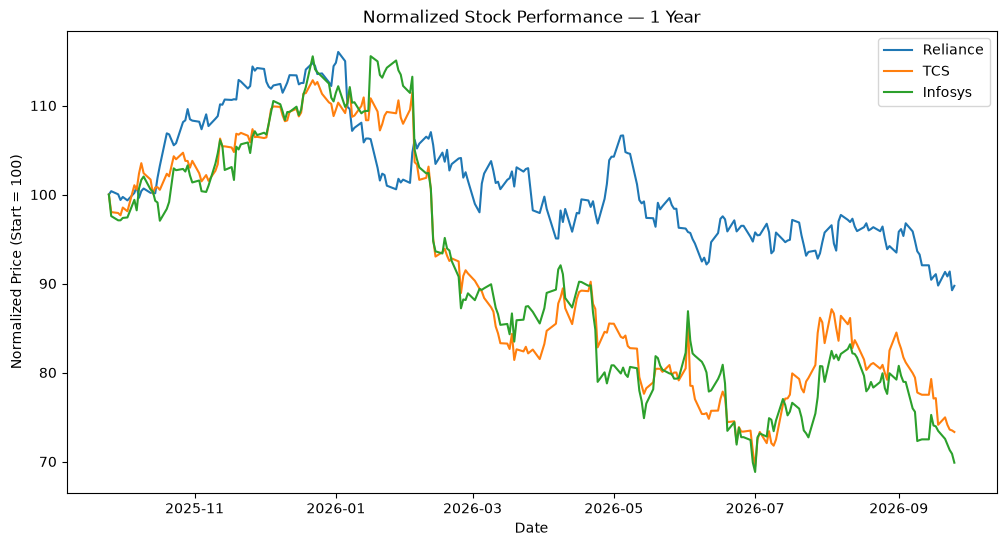

In [54]:
# Plot the normalized closing prices of all three stocks.
# Starting each stock at 100 makes their relative performance directly comparable.

plt.figure(figsize=(12, 6))

plt.plot(reliance_normalized, label="Reliance")
plt.plot(tcs_normalized, label="TCS")
plt.plot(infy_normalized, label="Infosys")

plt.title("Normalized Stock Performance — 1 Year")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Start = 100)")
plt.legend()
plt.show()

In [55]:
# Calculate the final normalized value for each stock.
# This shows how much ₹100 invested at the beginning would be worth at the end,
# ignoring dividends, taxes, brokerage, and other costs.

print("Reliance final value:", reliance_normalized.iloc[-1])
print("TCS final value:", tcs_normalized.iloc[-1])
print("Infosys final value:", infy_normalized.iloc[-1])

Reliance final value: 89.74558838076344
TCS final value: 73.32217549334578
Infosys final value: 69.87384630367333


In [56]:
# Calculate the total percentage return over the one-year period.
# This measures how much each stock's price changed from the first trading day to the last.

reliance_total_return = (reliance_close.iloc[-1] / reliance_close.iloc[0]) - 1
tcs_total_return = (tcs_close.iloc[-1] / tcs_close.iloc[0]) - 1
infy_total_return = (infy_close.iloc[-1] / infy_close.iloc[0]) - 1

print("Reliance total return:", reliance_total_return * 100, "%")
print("TCS total return:", tcs_total_return * 100, "%")
print("Infosys total return:", infy_total_return * 100, "%")

Reliance total return: -10.254411619236558 %
TCS total return: -26.67782450665421 %
Infosys total return: -30.126153696326675 %


In [57]:
# Add the total price return of each stock to the comparison table.
# This gives us an additional measure of overall performance.

comparison["Total Return"] = [
    reliance_total_return * 100,
    tcs_total_return * 100,
    infy_total_return * 100
]

comparison

,Stock,Average Daily Return,Volatility,Best Day,Worst Day,Maximum Drawdown,Total Return
0,Reliance,-0.034741,1.294520,3.529072,-4.599813,-23.077499,-10.254412
1,TCS,-0.107659,1.780938,6.507358,-8.386122,-38.463942,-26.677825
2,Infosys,-0.125035,1.881027,5.679839,-7.258455,-40.429562,-30.126154


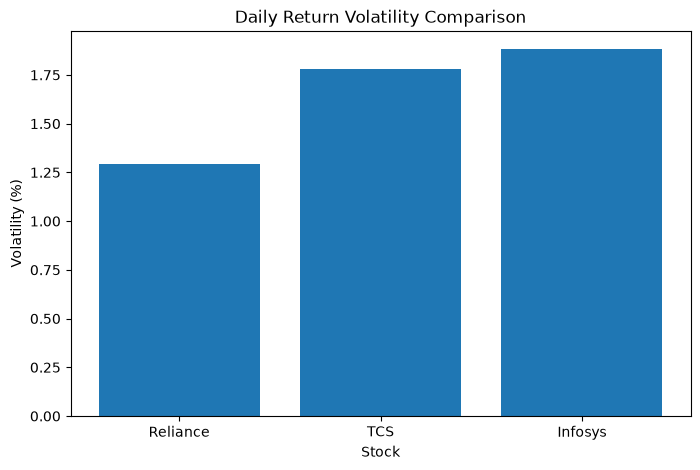

In [58]:
# Plot the historical daily volatility of the three stocks.
# This allows us to visually compare how much their daily returns fluctuated.

stocks = ["Reliance", "TCS", "Infosys"]
volatilities = [
    reliance_avg_return * 0 + data["Return"].std() * 100,
    tcs_volatility * 100,
    infy_volatility * 100
]

plt.figure(figsize=(8, 5))
plt.bar(stocks, volatilities)

plt.title("Daily Return Volatility Comparison")
plt.xlabel("Stock")
plt.ylabel("Volatility (%)")
plt.show()

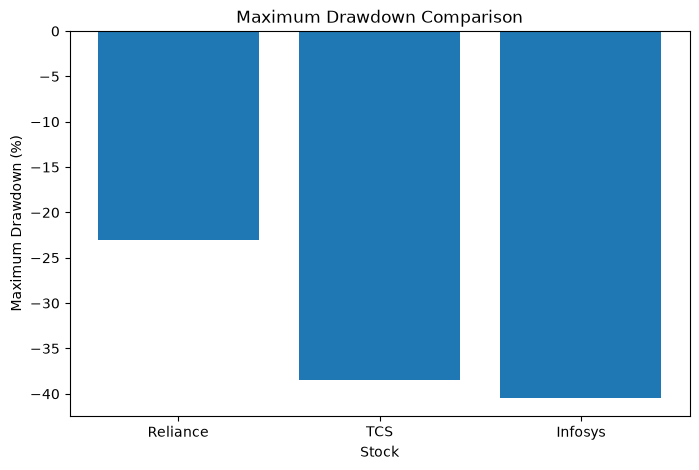

In [59]:
# Plot the maximum drawdown of each stock.
# More negative values represent larger historical declines from previous peaks.

drawdowns = [
    reliance_max_drawdown * 100,
    tcs_max_drawdown * 100,
    infy_max_drawdown * 100
]

plt.figure(figsize=(8, 5))
plt.bar(stocks, drawdowns)

plt.title("Maximum Drawdown Comparison")
plt.xlabel("Stock")
plt.ylabel("Maximum Drawdown (%)")
plt.show()

In [60]:
# Create a clean summary table containing the main performance and risk metrics.
# This provides a single overview of the analysis.

final_comparison = pd.DataFrame({
    "Stock": stocks,
    "Total Return (%)": [
        reliance_total_return * 100,
        tcs_total_return * 100,
        infy_total_return * 100
    ],
    "Average Daily Return (%)": [
        data["Return"].mean() * 100,
        tcs_data["Return"].mean() * 100,
        infy_data["Return"].mean() * 100
    ],
    "Volatility (%)": [
        data["Return"].std() * 100,
        tcs_volatility * 100,
        infy_volatility * 100
    ],
    "Best Day (%)": [
        data["Return"].max() * 100,
        tcs_data["Return"].max() * 100,
        infy_data["Return"].max() * 100
    ],
    "Worst Day (%)": [
        data["Return"].min() * 100,
        tcs_data["Return"].min() * 100,
        infy_data["Return"].min() * 100
    ],
    "Maximum Drawdown (%)": [
        reliance_max_drawdown * 100,
        tcs_max_drawdown * 100,
        infy_max_drawdown * 100
    ]
})

final_comparison

,Stock,Total Return (%),Average Daily Return (%),Volatility (%),Best Day (%),Worst Day (%),Maximum Drawdown (%)
0,Reliance,-10.254412,-0.034741,1.294520,3.529072,-4.599813,-23.077499
1,TCS,-26.677825,-0.107659,1.780938,6.507358,-8.386122,-38.463942
2,Infosys,-30.126154,-0.125035,1.881027,5.679839,-7.258455,-40.429562


In [61]:
# Check the folder where Python is currently running.
# This helps us understand how relative file paths are being interpreted.

import os

print(os.getcwd())

C:\Users\akilb\OneDrive\Desktop\stock-price-eda


In [62]:
# Save the final comparison table inside the project's outputs folder.

final_comparison.to_csv("outputs/stock_comparison.csv", index=False)

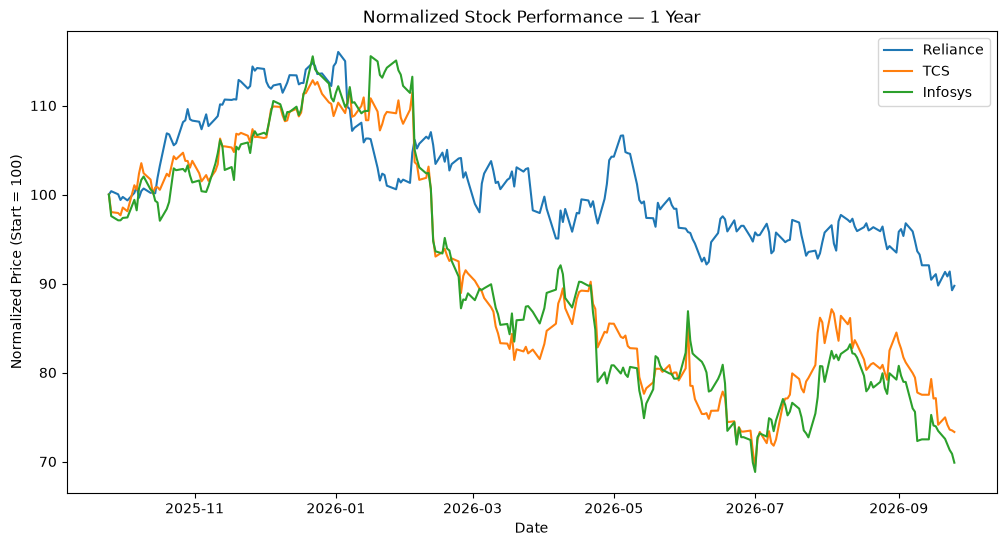

In [63]:
# Save the normalized stock performance chart.
# This allows us to reuse the chart in the GitHub README and LinkedIn post.

plt.figure(figsize=(12, 6))

plt.plot(reliance_normalized, label="Reliance")
plt.plot(tcs_normalized, label="TCS")
plt.plot(infy_normalized, label="Infosys")

plt.title("Normalized Stock Performance — 1 Year")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Start = 100)")
plt.legend()

plt.savefig("outputs/normalized_performance.png", dpi=300, bbox_inches="tight")
plt.show()

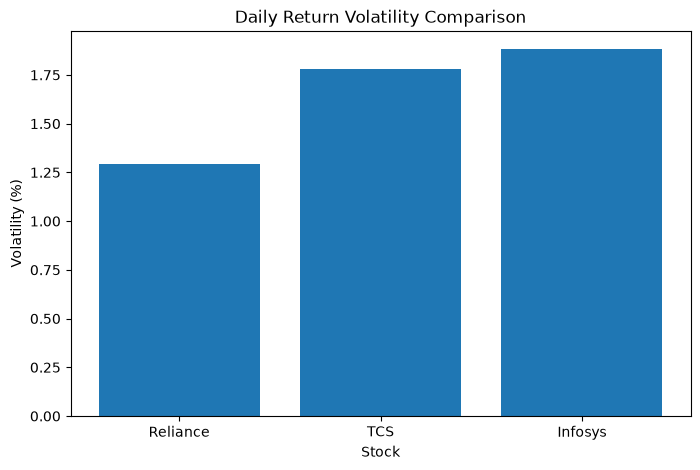

In [64]:
# Save the volatility comparison chart.
# This visualizes the historical daily return variability of each stock.

plt.figure(figsize=(8, 5))

plt.bar(stocks, volatilities)

plt.title("Daily Return Volatility Comparison")
plt.xlabel("Stock")
plt.ylabel("Volatility (%)")

plt.savefig("outputs/volatility_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

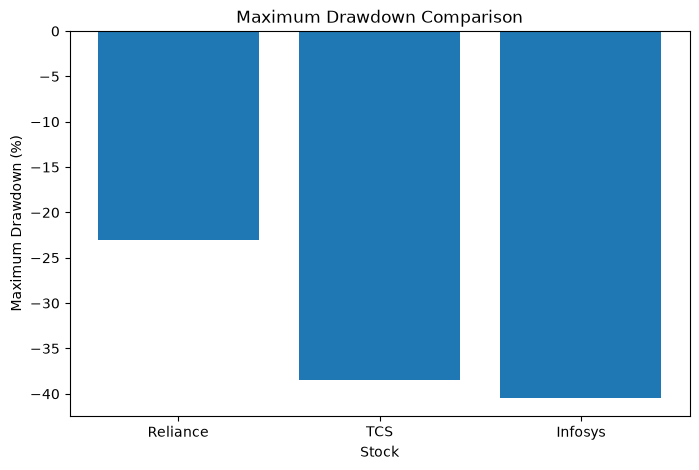

In [65]:
# Save the maximum drawdown comparison chart.
# This visualizes the largest decline from a previous peak for each stock.

plt.figure(figsize=(8, 5))

plt.bar(stocks, drawdowns)

plt.title("Maximum Drawdown Comparison")
plt.xlabel("Stock")
plt.ylabel("Maximum Drawdown (%)")

plt.savefig("outputs/drawdown_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
"""
## Conclusion

### Overall Performance

- Analyzed the historical price behavior of Reliance Industries, TCS,
  and Infosys using approximately one year of daily market data.
  
- All three stocks recorded negative total returns during the analyzed
  period.
  
- Reliance: -10.25%
- TCS: -26.68%
- Infosys: -30.13%

### Daily Return and Volatility

- Reliance recorded a historical daily volatility of 1.29%.

- TCS recorded a historical daily volatility of 1.78%
.
- Infosys recorded a historical daily volatility of 1.88%.

- The largest positive daily movement was +6.51% for TCS.

- The largest negative daily movement was -8.39% for TCS.

- These results show that individual trading days experienced
  considerable price movements.

### Maximum Drawdown

- Reliance recorded a maximum drawdown of -23.08%.

- TCS recorded a maximum drawdown of -38.46%.

- Infosys recorded a maximum drawdown of -40.43%.

- The drawdown analysis shows how far each stock declined from a
  previous closing-price peak during the selected period.

### Key Inferences

- Total return, volatility, and drawdown describe different aspects
  of stock behavior.
  
- Total return measures the overall price change during the period.

- Volatility measures the variability of daily returns.

- Drawdown measures the decline from a previous peak.

- Looking at these metrics together provides a more complete view
  of historical stock performance and risk.
  
- The analysis also shows that lower daily volatility does not
  necessarily mean that a stock cannot experience a significant
  decline from a previous peak.

### Project Learning

- Gained practical experience in collecting historical market data.

- Used Python and Pandas to calculate financial metrics.

- Used Matplotlib to visualize stock performance and risk.

- Learned how daily returns, volatility, and drawdown are calculated
  and interpreted.
  
- Learned how to compare multiple stocks using quantitative evidence.

- Learned the importance of considering limitations when interpreting
  financial data.

### Limitations
- The analysis covers approximately one year of historical data.

- Only three stocks were included.

- The analysis focuses mainly on historical price behavior.

- Dividends, taxes, brokerage charges, and transaction costs were not
  included in the simple price-return calculation.
  
- Historical results do not guarantee future performance.

### Final Note
- The findings represent historical observations from the selected
  dataset and observation period.
  
- They should not be interpreted as predictions of future stock
  performance or as investment advice.
"""